# Predicting NYC Taxi Trip Duration 
**Dataset:** NYC taxi trips, March 2019 (6,433-trip sample of NYC TLC trip records, distributed with seaborn)

**Problem:** A dispatcher or rider app needs an accurate estimate of how many minutes a trip will take *before* it starts. Can we predict trip duration from the trip's distance, time and location?

This notebook covers data loading, cleaning, exploration and an initial baseline model.

## 1. Setup and load data

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
from scipy.stats import loguniform, randint
import time
sns.set_theme(style='whitegrid'); RANDOM_STATE = 42

URL = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv'
df = pd.read_csv(URL, parse_dates=['pickup','dropoff'])
print('Shape:',df.shape)
df.head()

Shape: (6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


## 2. Target and data quality checks
The target is trip **duration in minutes** (dropoff time minus pickup time).

In [3]:
df['duration'] = (df['dropoff'] - df['pickup']).dt.total_seconds() / 60
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())
print('Trips under 1 minute :', (df['duration'] < 1).sum())
print('Trips with 0 distance:', (df['distance'] == 0).sum())
print('Trips with 0 passengers:', (df['passengers'] == 0).sum())
print('Date range:', df['pickup'].min().date(), 'to', df['pickup'].max().date())
df[['duration','distance','passengers']].describe().round(2)

Missing values per column:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Duplicate rows: 0
Trips under 1 minute : 72
Trips with 0 distance: 51
Trips with 0 passengers: 96
Date range: 2019-02-28 to 2019-03-31


,duration,distance,passengers
count,6433.00,6433.00,6433.00
mean,14.35,3.02,1.54
std,11.64,3.83,1.20
min,0.00,0.00,0.00
25%,6.50,0.98,1.00
50%,10.90,1.64,1.00
75%,18.52,3.21,2.00
max,107.67,36.70,6.00


## 3. Exploratory data analysis

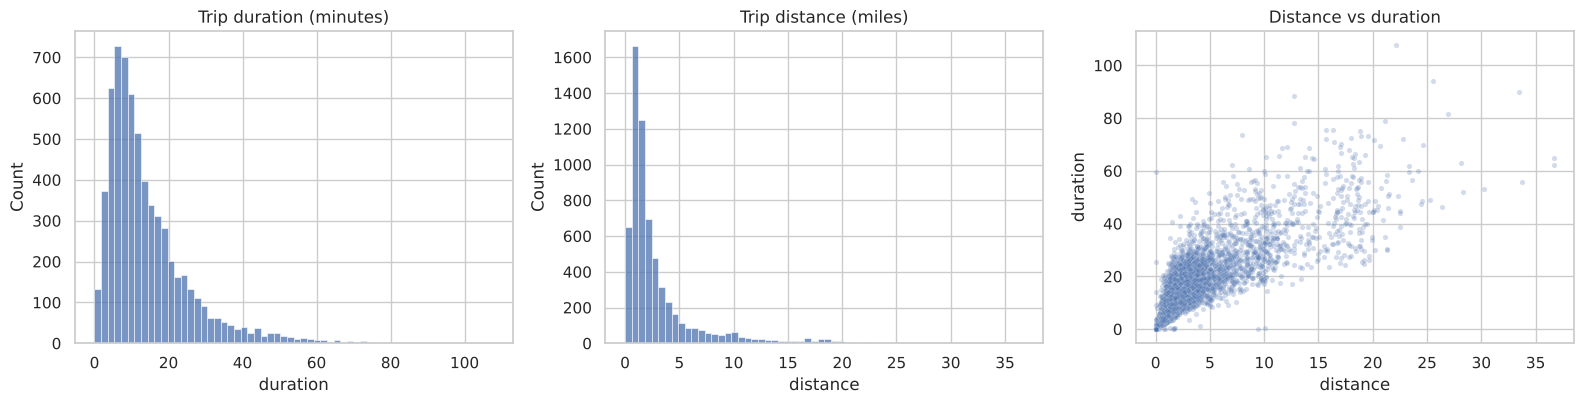

Correlation, distance vs duration: 0.821


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(df['duration'], bins=60, ax=ax[0]); ax[0].set_title('Trip duration (minutes)')
sns.histplot(df['distance'], bins=60, ax=ax[1]); ax[1].set_title('Trip distance (miles)')
sns.scatterplot(x='distance', y='duration', data=df, alpha=0.25, s=14, ax=ax[2]); ax[2].set_title('Distance vs duration')
plt.tight_layout(); plt.show()
print('Correlation, distance vs duration: %.3f' % df[['distance','duration']].corr().iloc[0,1])

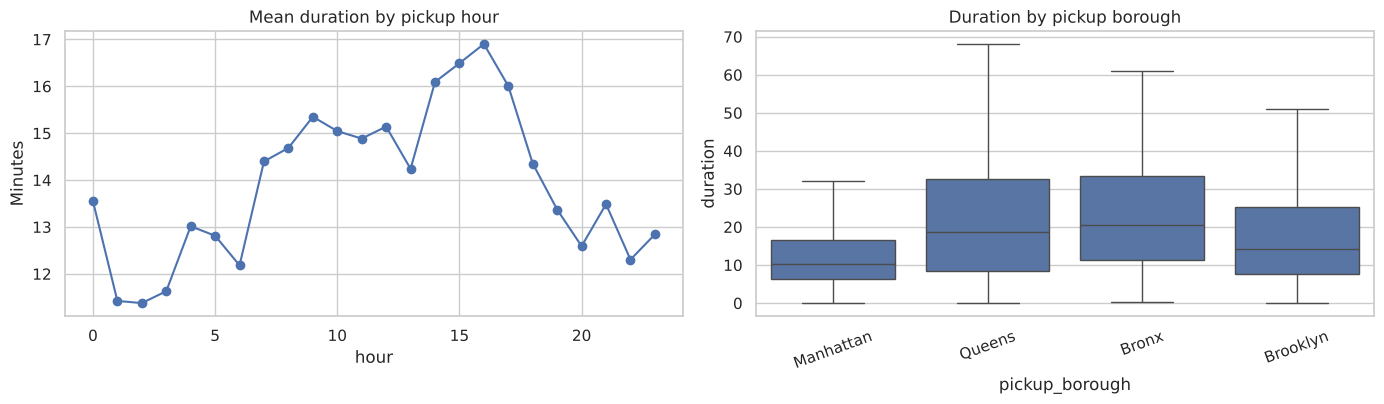

In [5]:
df['hour'] = df['pickup'].dt.hour
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
df.groupby('hour')['duration'].mean().plot(marker='o', ax=ax[0]); ax[0].set_title('Mean duration by pickup hour'); ax[0].set_ylabel('Minutes')
sns.boxplot(x='pickup_borough', y='duration', data=df, ax=ax[1], showfliers=False); ax[1].set_title('Duration by pickup borough'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## 4. Cleaning and feature engineering

In [ ]:
clean = df.copy()
before = len(clean)
#Remove trips that are under 1 minute or zero distance. These are not plausible trips and likely represent data entry errors or anomalies.s
clean = clean[(clean['duration'] >= 1) & (clean['distance'] > 0)].copy()
print('Rows removed:', before - len(clean), '| rows kept:', len(clean))

#For missing location/payment fields, mark them as unknown instead of dropping the records.
for c in ['pickup_borough','dropoff_borough','pickup_zone','dropoff_zone','payment']:
    clean[c] = clean[c].fillna('Unknown')
#0 passengers is a data entry artifact:set to 1
clean['passengers'] = clean['passengers'].clip(lower=1)

clean['hour'] = clean['pickup'].dt.hour
clean['dayofweek'] = clean['pickup'].dt.dayofweek
clean['is_weekend'] = (clean['dayofweek'] >= 5).astype(int)
clean['is_rush'] = (((clean['hour'].between(7, 9)) | (clean['hour'].between(16, 19))) & (clean['is_weekend'] == 0)).astype(int)
clean['same_borough'] = (clean['pickup_borough'] == clean['dropoff_borough']).astype(int)
print(clean[['duration','distance','hour','is_rush','same_borough']].describe().round(2))

Rows removed: 83 | rows kept: 6350
       duration  distance     hour  is_rush  same_borough
count   6350.00   6350.00  6350.00  6350.00       6350.00
mean      14.51      3.06    13.88     0.28          0.87
std       11.60      3.84     6.07     0.45          0.34
min        1.00      0.09     0.00     0.00          0.00
25%        6.65      1.00    10.00     0.00          1.00
50%       11.00      1.67    15.00     0.00          1.00
75%       18.60      3.25    19.00     1.00          1.00
max      107.67     36.70    23.00     1.00          1.00


In [ ]:
#Leakage check: fare, tip, tolls and total are only known after the trip.So they are NOT used as inputs.
BASE_NUM = ['distance','passengers','hour','dayofweek','is_weekend','is_rush','same_borough']
BASE_CAT = ['color','pickup_borough','dropoff_borough']
ZONE_CAT = ['pickup_zone','dropoff_zone']
X = clean[BASE_NUM + BASE_CAT + ZONE_CAT]; y = clean['duration']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Mean duration  train: %.2f   test: %.2f min' % (y_train.mean(), y_test.mean()))

prep_base = ColumnTransformer([('num', StandardScaler(), BASE_NUM),
                               ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), BASE_CAT)])

Train: (5080, 12)  Test: (1270, 12)
Mean duration  train: 14.49   test: 14.63 min


## 5. Initial model

In [8]:
def evaluate(name, model, Xt=None):
    Xt = X_test if Xt is None else Xt
    p = model.predict(Xt)
    return {'Model': name, 'MAE (min)': mean_absolute_error(y_test, p),
            'RMSE (min)': np.sqrt(mean_squared_error(y_test, p)), 'R²': r2_score(y_test, p),
            'Median abs. error (min)': median_absolute_error(y_test, p)}

dummy = Pipeline([('prep', prep_base), ('reg', DummyRegressor(strategy='mean'))]).fit(X_train, y_train)
lin   = Pipeline([('prep', prep_base), ('reg', LinearRegression())]).fit(X_train, y_train)
results1 = pd.DataFrame([evaluate('Mean-duration baseline', dummy), evaluate('Linear regression (initial)', lin)]).set_index('Model').round(3)
results1

,MAE (min),RMSE (min),R²,Median abs. error (min)
Model,,,,
Mean-duration baseline,8.707,12.391,-0.000,6.945
Linear regression (initial),4.560,6.566,0.719,3.403


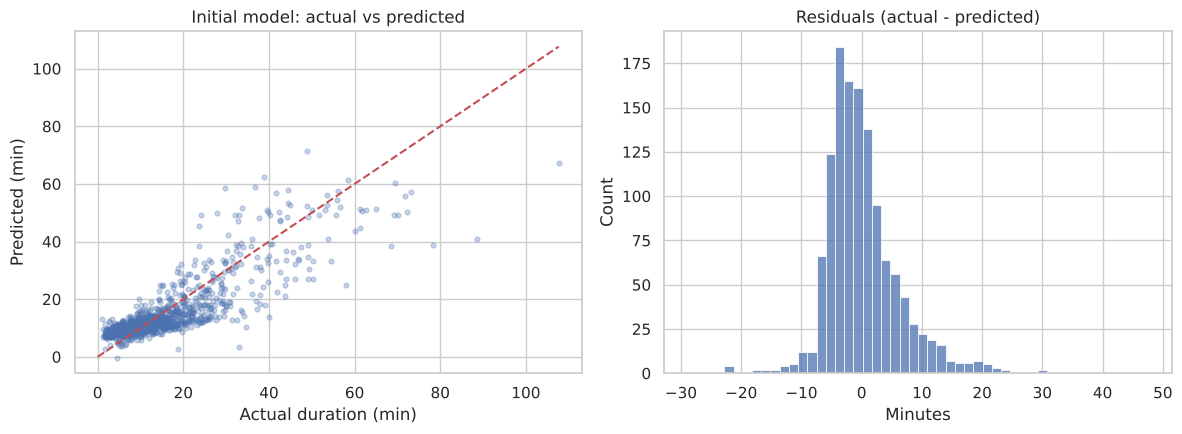

cat__dropoff_borough_Staten Island   -11.31
cat__dropoff_borough_Unknown          -6.27
cat__pickup_borough_Queens            -3.34
num__is_weekend                       -0.67
cat__dropoff_borough_Bronx             3.81
cat__dropoff_borough_Manhattan         4.56
cat__dropoff_borough_Brooklyn          5.84
num__distance                          9.46
dtype: float64


In [9]:
p_lin = lin.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, p_lin, alpha=0.3, s=12); lim = [0, max(y_test.max(), p_lin.max())]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Actual duration (min)'); ax[0].set_ylabel('Predicted (min)'); ax[0].set_title('Initial model: actual vs predicted')
sns.histplot(y_test - p_lin, bins=50, ax=ax[1]); ax[1].set_title('Residuals (actual - predicted)'); ax[1].set_xlabel('Minutes')
plt.tight_layout(); plt.show()
coef = pd.Series(lin.named_steps['reg'].coef_, index=lin.named_steps['prep'].get_feature_names_out()).sort_values()
print(pd.concat([coef.head(4), coef.tail(4)]).round(2))

## 6. Observations and next steps
- Distance alone explains most of the variation.So the linear model is a strong baseline but it assumes a straight line relationship.
- Residuals fan out for long trips.The target is right-skewed.So a log transform and non-linear models are the first things to try.
- Next: add pickup/dropoff zones, compare tree-based models with cross-validation, tune hyperparameters and audit errors by borough and time of day.